# CV nhẹ — benchmark cô lập (Arduino UNO Q 4GB)

- Export model sang **ONNX** (một lần), chạy bằng **onnxruntime CPU** trong tiến trình con (không import torch) → RAM sát thiết bị thật.
- Phân loại: MobileNetV3 / EfficientNet-Lite0. Phát hiện: YOLOv8n, YOLO11n @640, YOLO11n @320. OCR: RapidOCR (ONNX), Tesseract.
- **Bỏ captioning/VLM** (GIT, SmolVLM, Florence-2 ≥ 500MB). Thay bằng: detection + OCR → đưa text cho SLM mô tả.
- Token HF lấy từ biến môi trường `HF_TOKEN`, không ghi vào notebook.

In [1]:
%pip install -q onnx onnxruntime timm ultralytics rapidocr-onnxruntime pytesseract jiwer pillow psutil pandas matplotlib "datasets>=2.20.0"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys; sys.path.insert(0, ".")
from bench_common import *

def export(kind, params):
    r = run_isolated(kind, params)
    assert "error" not in r, r["error"]
    return r

## 1. Phân loại ảnh (ImageNet-1k, 500 ảnh)

In [3]:
IMG = prep_imagenet(500)
CLS = {
    "MobileNetV3-Small":  "mobilenetv3_small_100.lamb_in1k",
    "MobileNetV3-Large":  "mobilenetv3_large_100.ra_in1k",
    "EfficientNet-Lite0": "efficientnet_lite0.ra_in1k",
}
for name, tn in CLS.items():
    onnx = f"models/cv/{name}.onnx"
    if not Path(onnx).exists():
        export("export_timm", {"timm_name": tn, "out": onnx})
    bench("cv_classification", name, "cls_ort", {"onnx": onnx, "data_dir": IMG})
table("cv_classification")

Chưa có HF_TOKEN — nếu cần dataset gated (ImageNet), chạy `huggingface-cli login` trước.


Resolving data files:   0%|          | 0/294 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/294 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

[done] MobileNetV3-Small: ram_peak_mb=49.0, ram_total_peak_mb=84.0, top1_acc=0.714, ms_per_image=1.0
[done] MobileNetV3-Large: ram_peak_mb=69.6, ram_total_peak_mb=104.5, top1_acc=0.776, ms_per_image=1.9
[done] EfficientNet-Lite0: ram_peak_mb=64.9, ram_total_peak_mb=100.0, top1_acc=0.778, ms_per_image=2.4


,model,ram_runtime_mb,ram_model_load_mb,ram_peak_mb,ram_total_peak_mb,top1_acc,ms_per_image,n_samples,onnx_mb,runtime
0,EfficientNet-Lite0,35.1,25.4,64.9,100.0,0.778,2.4,500,17.7,onnxruntime
1,MobileNetV3-Large,34.9,30.0,69.6,104.5,0.776,1.9,500,20.9,onnxruntime
2,MobileNetV3-Small,35.0,19.4,49.0,84.0,0.714,1.0,500,9.7,onnxruntime


## 2. Phát hiện vật thể (COCO128)
`ort_footprint` = RAM sạch của model ONNX (không torch). `det_yolo_val` = mAP (ultralytics kéo torch nên RAM runtime lớn — bỏ qua cột RAM của dòng này).

In [4]:
DET = {"YOLOv8n-640": ("yolov8n.pt", 640), "YOLO11n-640": ("yolo11n.pt", 640), "YOLO11n-320": ("yolo11n.pt", 320)}
for name, (w, sz) in DET.items():
    onnx = f"models/cv/{name}.onnx"
    if not Path(onnx).exists():
        export("export_yolo", {"weights": w, "imgsz": sz, "out": onnx})
    fp = bench("cv_detection_ram", name, "ort_footprint", {"onnx": onnx, "shape": [1, 3, sz, sz]})
    mp = bench("cv_detection_map", name, "det_yolo_val", {"onnx": onnx, "imgsz": sz})
    if "error" not in fp and "error" not in mp:
        update_row("cv_detection_ram", name, map50_95=mp["map50_95"], map50=mp["map50"])
table("cv_detection_ram")

[done] YOLOv8n-640: ram_peak_mb=79.0, ram_total_peak_mb=110.5, ms_per_image=24.7
[done] YOLOv8n-640: ram_peak_mb=209.2, ram_total_peak_mb=402.5, map50_95=0.4513
[done] YOLO11n-640: ram_peak_mb=103.8, ram_total_peak_mb=135.4, ms_per_image=22.0
[done] YOLO11n-640: ram_peak_mb=234.4, ram_total_peak_mb=428.0, map50_95=0.5051
[done] YOLO11n-320: ram_peak_mb=44.6, ram_total_peak_mb=76.0, ms_per_image=6.2
[done] YOLO11n-320: ram_peak_mb=172.4, ram_total_peak_mb=365.7, map50_95=0.3852


,model,ram_runtime_mb,ram_model_load_mb,ram_peak_mb,ram_total_peak_mb,load_s,ms_per_image,onnx_mb,runtime,map50_95,map50
0,YOLO11n-320,31.3,20.9,44.6,76.0,0.05,6.2,10.1,onnxruntime,0.3852,0.5285
1,YOLO11n-640,31.6,21.0,103.8,135.4,0.06,22.0,10.2,onnxruntime,0.5051,0.6744
2,YOLOv8n-640,31.5,21.6,79.0,110.5,0.04,24.7,12.2,onnxruntime,0.4513,0.6043


## 3. OCR (chữ in tổng hợp có xoay/mờ/nhiễu)

In [5]:
OCRD = render_ocr_set()
bench("cv_ocr", "RapidOCR (onnx)", "ocr_rapid", {"data_dir": OCRD})
bench("cv_ocr", "Tesseract", "ocr_tesseract", {"data_dir": OCRD})   # cần cài Tesseract; đặt TESSERACT_CMD nếu khác mặc định
table("cv_ocr")

[done] RapidOCR (onnx): ram_peak_mb=453.1, ram_total_peak_mb=500.9, cer=0.0782, ms_per_image=369.5
[done] Tesseract: cer=0.0327, ms_per_image=90.2, ram_total_peak_mb=80.0


,model,ram_runtime_mb,ram_model_load_mb,ram_peak_mb,ram_total_peak_mb,load_s,cer,ms_per_image,n_samples,runtime,ram_note
0,RapidOCR (onnx),47.8,35.7,453.1,500.9,0.26,0.0782,369.5,40,onnxruntime(rapidocr),NaN
1,Tesseract,NaN,NaN,NaN,80.0,NaN,0.0327,90.2,40,tesseract,ước lượng (tiến trình ngoài) — hãy đo lại


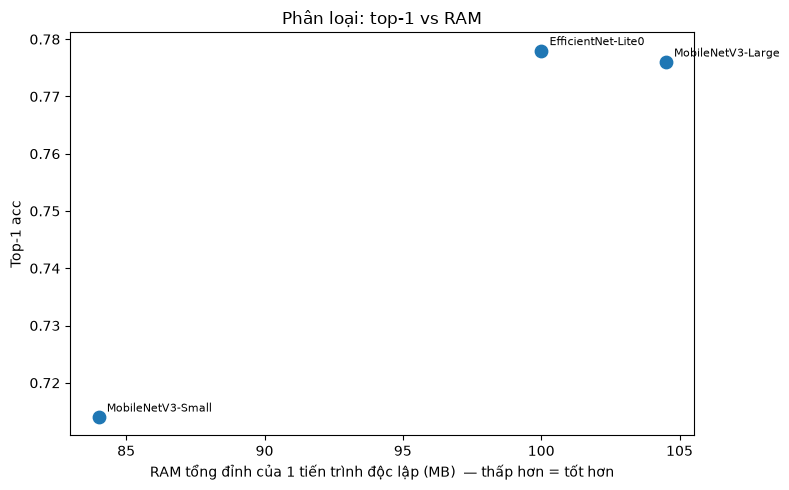

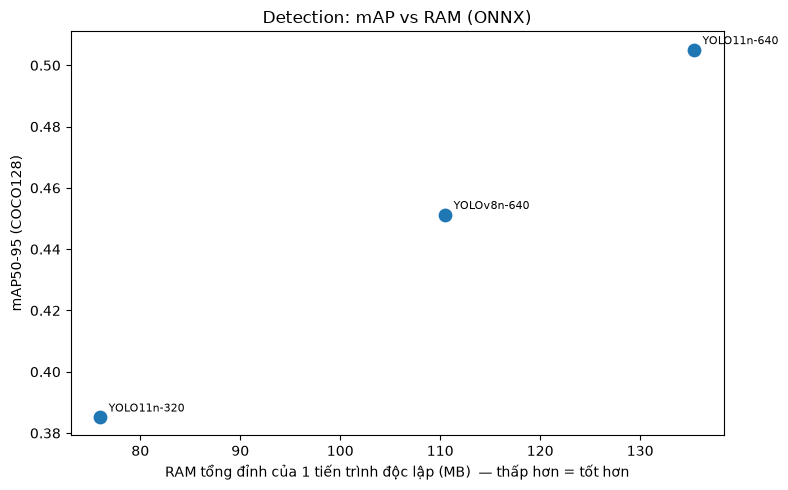

In [6]:
plot_tradeoff(table("cv_classification"), "ram_total_peak_mb", "top1_acc", "Phân loại: top-1 vs RAM", "Top-1 acc", "cv_cls.png")
plot_tradeoff(table("cv_detection_ram"), "ram_total_peak_mb", "map50_95", "Detection: mAP vs RAM (ONNX)", "mAP50-95 (COCO128)", "cv_det.png")

## Lưu ý
- mAP COCO128 và CER chữ tổng hợp chỉ để **so tương đối**; chụp thêm ảnh thật từ camera UNO Q trước khi chốt.
- ONNX fp32 đủ nhẹ cho các model này; nếu cần nhỏ hơn nữa có thể thử quantize int8 (cần kiểm tra lại accuracy).
- Số đo trên PC x86; ms/ảnh trên UNO Q sẽ chậm hơn nhiều.